# Part 1: Hyperparameters, dataset and VAE training

In [19]:
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import save_image

seed = 285
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

root = Path.home() / "Desktop/ECE 285/Homework 1"
data_dir = root / "chest_xray"
if not (data_dir / "train").is_dir():
    data_dir = data_dir / "chest_xray"
output_dir = root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

image_size = 128
latent_dim = 64
batch_size = 32
epochs = 25
learning_rate = 1e-3
beta = 1.0
force_train = False  # Set True only to retrain the model

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor()
])

full_train = datasets.ImageFolder(data_dir / "train", transform=transform)
test_dataset = datasets.ImageFolder(data_dir / "test", transform=transform)

val_size = int(len(full_train) * 0.1)
train_dataset, val_dataset = random_split(
    full_train,
    [len(full_train) - val_size, val_size],
    generator=torch.Generator().manual_seed(seed)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print("Device:", device)
print("Dataset:", data_dir)
print("Train / Val / Test:", len(train_dataset), len(val_dataset), len(test_dataset))
print("Classes:", full_train.classes)

Device: mps
Dataset: /Users/huzichen/Desktop/ECE 285/Homework 1/chest_xray
Train / Val / Test: 4695 521 624
Classes: ['NORMAL', 'PNEUMONIA']


In [21]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU()
        )
        self.fc_mu = nn.Linear(256 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(256 * 8 * 8, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 256 * 8 * 8)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        return self.decoder(self.fc_decode(z).view(-1, 256, 8, 8))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


def vae_loss(recon, x, mu, logvar):
    reconstruction = F.mse_loss(recon, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp()) / x.size(0)
    return reconstruction + beta * kl, reconstruction, kl


model = ConvVAE(latent_dim).to(device)
checkpoint_path = output_dir / "best_vae.pt"
history_path = output_dir / "training_history.json"
legacy_path = output_dir / "results.json"

In [22]:
saved_file = history_path if history_path.exists() else legacy_path
reuse_model = checkpoint_path.exists() and saved_file.exists() and not force_train

if reuse_model:
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    with open(saved_file) as f:
        previous = json.load(f)
    history = previous["history"]
    best_epoch = previous["best_epoch"]
    best_val = previous["best_validation_loss"]
    print(f"Loaded previously trained model (best epoch {best_epoch}, val loss {best_val:.4f}).")
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {f"{split}_{kind}": [] for split in ["train", "val"]
               for kind in ["total", "recon", "kl"]}
    best_val = float("inf")
    best_epoch = 0

    def run_epoch(loader, training):
        model.train(training)
        totals = np.zeros(3)
        count = 0

        for x, _ in loader:
            x = x.to(device)
            if training:
                optimizer.zero_grad()
            with torch.set_grad_enabled(training):
                recon, mu, logvar = model(x)
                loss, rec, kl = vae_loss(recon, x, mu, logvar)
                if training:
                    loss.backward()
                    optimizer.step()
            totals += np.array([loss.item(), rec.item(), kl.item()]) * x.size(0)
            count += x.size(0)

        return totals / count

    for epoch in range(epochs):
        train_values = run_epoch(train_loader, True)
        val_values = run_epoch(val_loader, False)

        for split, values in [("train", train_values), ("val", val_values)]:
            for name, value in zip(["total", "recon", "kl"], values):
                history[f"{split}_{name}"].append(float(value))

        if val_values[0] < best_val:
            best_val = float(val_values[0])
            best_epoch = epoch + 1
            torch.save(model.state_dict(), checkpoint_path)

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"Train {train_values[0]:.3f} | Val {val_values[0]:.3f}")

    with open(history_path, "w") as f:
        json.dump({
            "history": history, "best_epoch": best_epoch,
            "best_validation_loss": best_val
        }, f, indent=2)

    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))

model.eval()
print(f"Best epoch: {best_epoch} | Best validation loss: {best_val:.4f}")

Loaded previously trained model (best epoch 24, val loss 110.2730).
Best epoch: 24 | Best validation loss: 110.2730


The VAE was initially trained for all 25 epochs; the model from epoch 24 was saved because its validation loss (110.2730) was the lowest over the training run, compared with 111.7960 at epoch 25. For this notebook execution, force_train = False reuses best_vae.pt and the per-epoch loss history stored in results.json to avoid repeating the approximately 10-minute training run. The entire training procedure is implemented in the preceding code cell; set force_train = True to retrain from scratch on the downloaded dataset. Thus, the selected epoch and plotted losses come from a recorded training run, not manually assigned values. I have also added the two files(best_vae.pt, results.json) in my Github.

# Part 2: Training loss curves

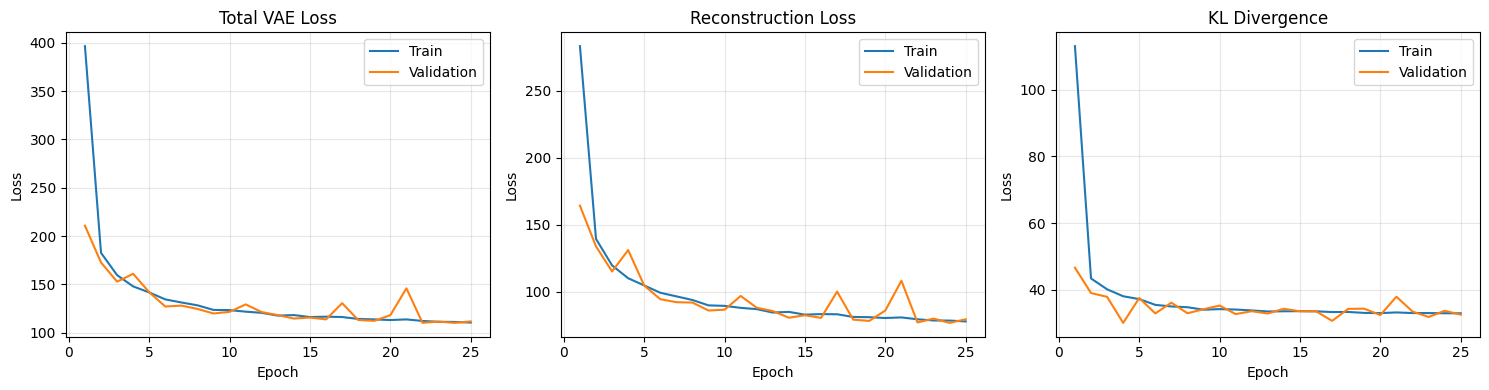

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name, title in zip(
    axes,
    ["total", "recon", "kl"],
    ["Total VAE Loss", "Reconstruction Loss", "KL Divergence"]
):
    x = np.arange(1, len(history[f"train_{name}"]) + 1)
    ax.plot(x, history[f"train_{name}"], label="Train")
    ax.plot(x, history[f"val_{name}"], label="Validation")
    ax.set(title=title, xlabel="Epoch", ylabel="Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(output_dir / "training_losses.png", dpi=300, bbox_inches="tight")
plt.show()

Total training loss fell from 396.49 to 110.60 over 25 epochs. Validation loss also decreased overall, with occasional fluctuations, suggesting successful convergence without sustained validation deterioration. The KL loss stayed positive, showing that the latent distribution regularizer remained active.

# Part 3: FID and inception score

In [26]:
from ignite.metrics import FID
from torchvision.models import inception_v3, Inception_V3_Weights

metric_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

inception = inception_v3(
    weights=Inception_V3_Weights.IMAGENET1K_V1
).to(metric_device).eval()
classifier = inception.fc
inception.fc = nn.Identity()  # 2048 pooled features instead of 1000 logits

def inception_input(x):
    x = F.interpolate(x, size=(299, 299), mode="bilinear",
                      align_corners=False, antialias=True)
    return x.repeat(1, 3, 1, 1) * 2 - 1

fid_metric = FID(
    num_features=2048,
    feature_extractor=nn.Identity(),
    device="cpu"
)
probabilities = []
generator = torch.Generator().manual_seed(seed + 1)

with torch.no_grad():
    for real, _ in test_loader:
        n = real.size(0)
        z = torch.randn(n, latent_dim, generator=generator).to(device)
        fake = model.decode(z).cpu()

        real_features = inception(
            inception_input(real.to(metric_device))
        )
        fake_features = inception(
            inception_input(fake.to(metric_device))
        )

        fid_metric.update((fake_features.cpu(), real_features.cpu()))

        logits = classifier(fake_features)
        probabilities.append(torch.softmax(logits, dim=1).cpu())

fid_score = float(fid_metric.compute())
p = torch.cat(probabilities).clamp_min(1e-12)
mean_p = p.mean(dim=0).clamp_min(1e-12)
is_score = torch.exp((p * (p.log() - mean_p.log())).sum(dim=1).mean()).item()

print(f"FID (2048 pooled torchvision Inception features): {fid_score:.4f}")
print(f"Inception Score: {is_score:.4f}")

evaluation = {
    "fid_pooled_2048": fid_score,
    "inception_score": is_score,
    "evaluation_samples": len(test_dataset),
    "feature_extractor": "torchvision InceptionV3 ImageNet-1K",
    "fid_features": "2048-dimensional pooled activations",
    "image_range_after_normalization": "[-1, 1]",
    "interpolation": "bilinear with antialiasing",
    "best_epoch": best_epoch,
    "best_validation_loss": best_val
}
with open(output_dir / "evaluation_updated.json", "w") as f:
    json.dump(evaluation, f, indent=2)

del inception, classifier, fid_metric

with open(output_dir / "results.json", "r") as f:
    results = json.load(f)

with open(output_dir / "evaluation_updated.json", "r") as f:
    evaluation = json.load(f)

results.pop("fid", None)
results.pop("inception_score", None)
results["evaluation"] = evaluation

with open(output_dir / "results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results updated successfully.")

FID (2048 pooled torchvision Inception features): 262.4125
Inception Score: 1.9429
Results updated successfully.


# Part 4: Generated and reconstructed X-ray examples

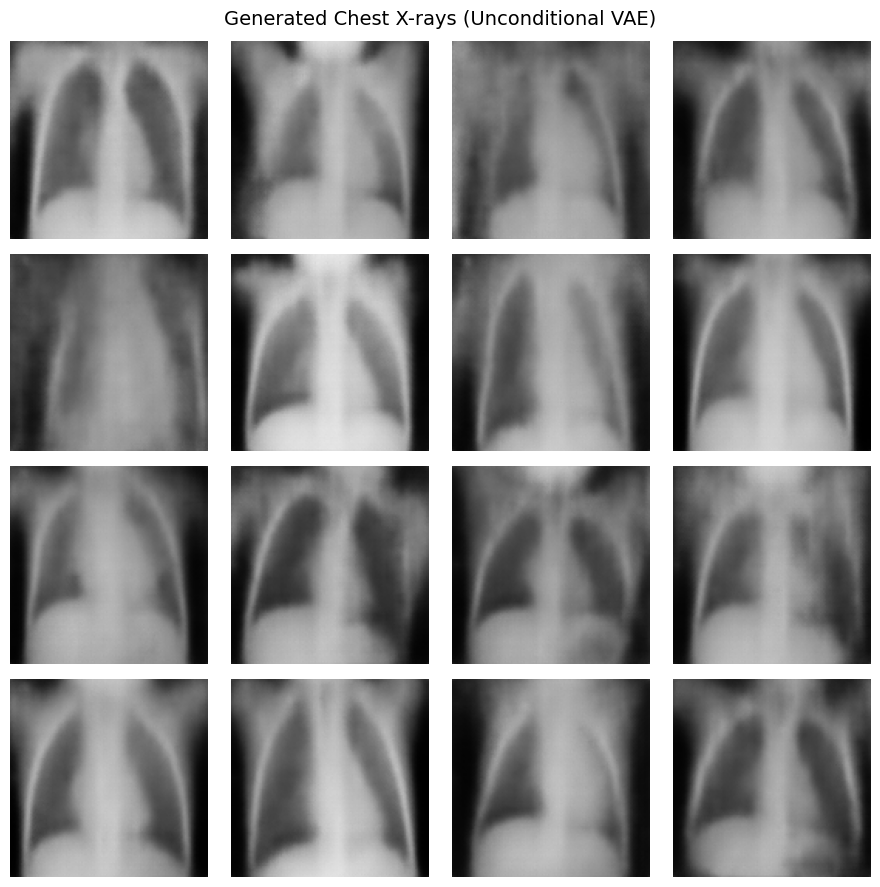

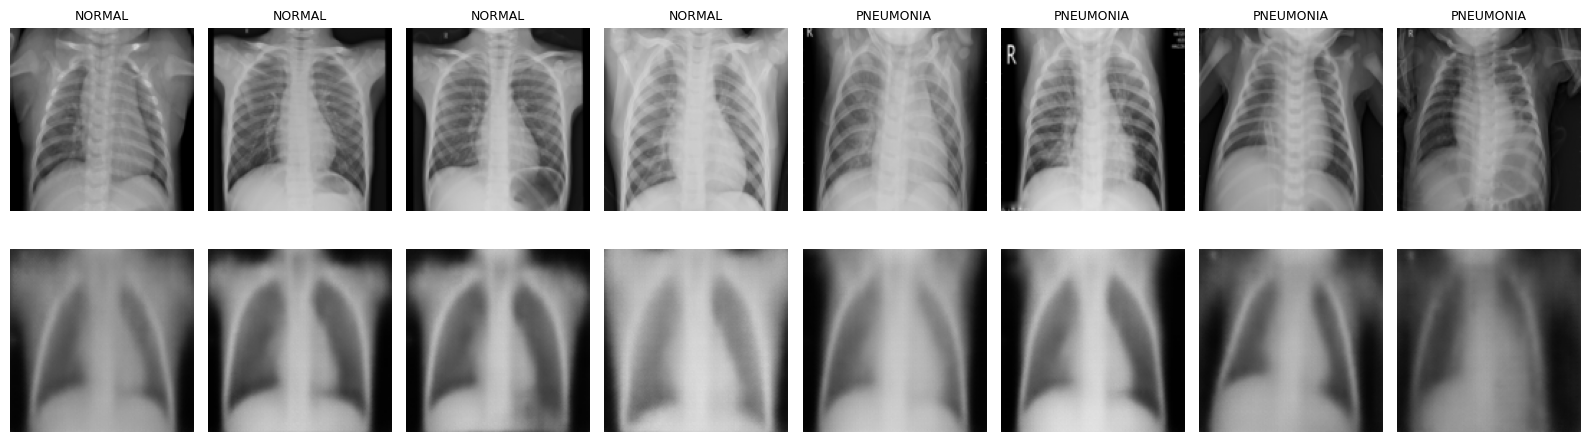

Figures and evaluation saved in: /Users/huzichen/Desktop/ECE 285/Homework 1/results


In [25]:
# Unconditional samples from the VAE prior
model.eval()
with torch.no_grad():
    z = torch.randn(16, latent_dim,
                    generator=torch.Generator().manual_seed(seed + 2)).to(device)
    generated = model.decode(z).cpu()

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Generated Chest X-rays (Unconditional VAE)", fontsize=14)
plt.tight_layout()
plt.savefig(output_dir / "generated_images.png", dpi=300, bbox_inches="tight")
plt.show()
save_image(generated, output_dir / "generated_grid.png", nrow=4)

# Select four test images from each class, rather than the first eight NORMAL images.
rng = random.Random(seed)
sample_indices = []
for class_id in range(len(test_dataset.classes)):
    pool = [i for i, (_, y) in enumerate(test_dataset.samples) if y == class_id]
    sample_indices.extend(rng.sample(pool, 4))

original = torch.stack([test_dataset[i][0] for i in sample_indices]).to(device)
labels = [test_dataset.classes[test_dataset.samples[i][1]] for i in sample_indices]

with torch.no_grad():
    mu, _ = model.encode(original)
    reconstructed = model.decode(mu).cpu()
original = original.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i, label in enumerate(labels):
    axes[0, i].imshow(original[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(label, fontsize=9)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)
plt.tight_layout()
plt.savefig(output_dir / "reconstruction.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figures and evaluation saved in:", output_dir)

Samples generated from the standard normal latent prior show recognizable lung silhouettes and chest anatomy, but are visibly blurry and often lack fine structures. Reconstructions cover examples from both NORMAL and PNEUMONIA test categories. These images demonstrate unconditional generation, not diagnostic accuracy or clinical usability.